In [1]:
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Dimensionality reduction
from sklearn.decomposition import PCA

# Model evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('Car_price_2024.csv')
df.head()

,Model,Year,Fuel_Type,Transmission,DoorsNum,Condition,Color,Cruise,Leather_Seats,Heated_Seats,...,Price,Cylinder_Numbers,Credit_History,Engine_Size,Weight,carlength,carwidth,monthly_mileage,peakrpm,Estimated_Mileage
0,Nissan Altima,2007,Petrol,Manual,4.0,Fair,Brown,No,No,No,...,8005.469674,two,0.004967,1.655688,3170.460434,179.1,68.1,3020.474750,6000,36245.697
1,Toyota Corolla,2019,Electric,Manual,4.0,Excellent,Beige,Yes,No,Yes,...,25385.241860,two,-0.001383,2.696626,3543.00629,182.1,60.0,894.742606,4689,10736.91127
2,Honda CR-V,2004,Petrol,Manual,4.0,Fair,Brown,No,No,No,...,6553.601733,three,0.006477,1.642471,3125.542396,161.0,67.5,3496.160436,5190,41953.92523
3,Toyota Corolla,2020,Electric,Manual,4.0,Good,Brown,Yes,Yes,Yes,...,24381.083350,three,0.015230,2.044309,3340.060049,169.7,65.2,1037.247974,5720,12446.97569
4,Toyota Tundra,2017,Hybrid,Automatic,4.0,Good,Brown,Yes,No,No,...,28357.830640,five,-0.002342,2.586011,3847.825597,176.0,68.1,880.045753,4559,10560.54904


# Data Cleaning

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Model              2230 non-null   str    
 1   Year               2230 non-null   int64  
 2   Fuel_Type          2227 non-null   str    
 3   Transmission       2223 non-null   str    
 4   DoorsNum           2223 non-null   float64
 5   Condition          2230 non-null   str    
 6   Color              2228 non-null   str    
 7   Cruise             2230 non-null   str    
 8   Leather_Seats      2230 non-null   str    
 9   Heated_Seats       2230 non-null   str    
 10  Navigation         2230 non-null   str    
 11  Owners             2230 non-null   int64  
 12  Insurance          2230 non-null   str    
 13  Service_History    2230 non-null   str    
 14  Safety             2230 non-null   str    
 15  Premium_Sound      2230 non-null   str    
 16  Multimedia         2230 non-null   

In [4]:
df.describe()

,Year,DoorsNum,Owners,Warranty,Price,Credit_History,Engine_Size,carlength,carwidth,monthly_mileage,peakrpm
count,2230.000000,2223.000000,2230.000000,2230.000000,2230.000000,2230.000000,2230.000000,2230.000000,2230.000000,2230.000000,2230.000000
mean,2009.702242,3.640126,5.117489,19.735874,17241.511048,0.000360,2.931071,175.439552,66.477309,1986.593741,5343.346637
std,5.676737,2.318487,9.643330,8.419290,8961.471367,0.009869,9.195792,19.677468,3.770973,994.408364,722.580399
min,2000.000000,2.000000,0.000000,6.000000,3527.516896,-0.032413,1.000000,141.000000,60.000000,-326.426931,4100.000000
25%,2005.000000,2.000000,2.000000,13.000000,8897.953205,-0.006230,2.020221,158.500000,63.100000,1116.573719,4721.250000
50%,2009.000000,4.000000,2.000000,19.000000,17393.385485,0.000253,2.284103,175.600000,66.500000,1758.514301,5324.500000
75%,2014.000000,4.000000,3.000000,27.000000,24067.296380,0.006728,2.553892,192.575000,69.800000,2940.711792,5969.000000
max,2022.000000,44.000000,44.000000,35.000000,51219.220660,0.038527,152.348978,209.000000,73.000000,4167.599834,6600.000000


In [5]:
df.isnull().sum()

Model                0
Year                 0
Fuel_Type            3
Transmission         7
DoorsNum             7
Condition            0
Color                2
Cruise               0
Leather_Seats        0
Heated_Seats         0
Navigation           0
Owners               0
Insurance            0
Service_History      0
Safety               0
Premium_Sound        0
Multimedia           0
Bluetooth            0
Wheel                0
Sunroof              0
Warranty             0
TAge                 0
Price                0
Cylinder_Numbers     0
Credit_History       0
Engine_Size          0
Weight               1
carlength            0
carwidth             0
monthly_mileage      0
peakrpm              0
Estimated_Mileage    0
dtype: int64

### Filling missing values

In [6]:
cols = ['Transmission', 'DoorsNum', 'Fuel_Type', 'Color']
df[cols] = df[cols].fillna(df[cols].mode().iloc[0])
# iloc provides the first row of the mode table if there are multiple modes

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Model              2230 non-null   str    
 1   Year               2230 non-null   int64  
 2   Fuel_Type          2230 non-null   str    
 3   Transmission       2230 non-null   str    
 4   DoorsNum           2230 non-null   float64
 5   Condition          2230 non-null   str    
 6   Color              2230 non-null   str    
 7   Cruise             2230 non-null   str    
 8   Leather_Seats      2230 non-null   str    
 9   Heated_Seats       2230 non-null   str    
 10  Navigation         2230 non-null   str    
 11  Owners             2230 non-null   int64  
 12  Insurance          2230 non-null   str    
 13  Service_History    2230 non-null   str    
 14  Safety             2230 non-null   str    
 15  Premium_Sound      2230 non-null   str    
 16  Multimedia         2230 non-null   

In [8]:
df['Weight'] = pd.to_numeric(df['Weight'], errors='coerce')

In [9]:
df['Weight'] = df['Weight'].fillna(df['Weight'].mean())

In [10]:
# For missing values, categorical features(Transmission, Fuel_Type, Color) and discrete counts(DorrsNum) are filled using the mode to 
# instead of mean as this prevents the values to be fractional or non-integer for this type of features.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Model              2230 non-null   str    
 1   Year               2230 non-null   int64  
 2   Fuel_Type          2230 non-null   str    
 3   Transmission       2230 non-null   str    
 4   DoorsNum           2230 non-null   float64
 5   Condition          2230 non-null   str    
 6   Color              2230 non-null   str    
 7   Cruise             2230 non-null   str    
 8   Leather_Seats      2230 non-null   str    
 9   Heated_Seats       2230 non-null   str    
 10  Navigation         2230 non-null   str    
 11  Owners             2230 non-null   int64  
 12  Insurance          2230 non-null   str    
 13  Service_History    2230 non-null   str    
 14  Safety             2230 non-null   str    
 15  Premium_Sound      2230 non-null   str    
 16  Multimedia         2230 non-null   

### Removing Whitespaces

In [12]:
object_columns = df.select_dtypes(['object'])
object_columns.columns

Index(['Model', 'Fuel_Type', 'Transmission', 'Condition', 'Color', 'Cruise',
       'Leather_Seats', 'Heated_Seats', 'Navigation', 'Insurance',
       'Service_History', 'Safety', 'Premium_Sound', 'Multimedia', 'Bluetooth',
       'Wheel', 'Sunroof', 'TAge', 'Cylinder_Numbers', 'Estimated_Mileage'],
      dtype='str')

In [13]:
columns = ['Model', 'Fuel_Type', 'Transmission', 'Condition', 'Color', 'Cruise',
       'Leather_Seats', 'Heated_Seats', 'Navigation', 'Insurance',
       'Service_History', 'Safety', 'Premium_Sound', 'Multimedia', 'Bluetooth',
       'Wheel', 'Sunroof', 'TAge', 'Cylinder_Numbers', 'Estimated_Mileage']
def checkUniqueValuesforList(dataframe, listColumns):
    '''
    Creating function to inspect unique values across specified object columns.
    It helps to identify typos and hidden whitespaces and helps determine which
    columns require cleaning or needs to be modified.
    '''
    for col in listColumns:
        unique_data = dataframe[col].unique()

        print(col)
        print('-'*35)
        print(unique_data)
        print('\n')

In [14]:
checkUniqueValuesforList(df, columns)

Model
-----------------------------------
<ArrowStringArray>
[     'Nissan Altima',     'Toyota Corolla',         'Honda CR-V',
      'Toyota Tundra',        'Ford Fusion',        'Ford Escape',
        'Nissan GT-R',     'Chevrolet Volt',       'Toyota Prius',
     'Chevrolet Bolt',   'Chevrolet Impala',        'Honda Pilot',
       'Toyota Camry',      'Toyota Camary',        'Nissan Juke',
      'Nissan Murano', 'Chevrolet Corvette',       'Honda Accord',
   'Chevrolet Camaro',        'Nissan 350Z',    'Chevrolet Sonic',
       'Ford Mustang',          'Honda Fit',       'Nissan Titan']
Length: 24, dtype: str


Fuel_Type
-----------------------------------
<ArrowStringArray>
['Petrol', 'Electric', 'Hybrid', 'Petroll']
Length: 4, dtype: str


Transmission
-----------------------------------
<ArrowStringArray>
['Manual', 'Automatic', 'Na', 'AutoNamatic']
Length: 4, dtype: str


Condition
-----------------------------------
<ArrowStringArray>
['Fair', 'Excellent', 'Good', 'Excellent!',

In [15]:
# removing whitespaces in service_history column(we get error in excell
# because of this whitespaces)
df['Service_History'] = df['Service_History'].astype(str).str.strip()

In [16]:
# Strip hidden spaces first in condition column
df['Condition'] = df['Condition'].astype(str).str.strip()

In [17]:
# Strip hidden spaces first in color column
df['Color'] = df['Color'].astype(str).str.strip()

In [18]:
# Strip whitespace for cylinder numbers
df['Cylinder_Numbers'] = df['Cylinder_Numbers'].astype(str).str.strip()

In [19]:
df['Estimated_Mileage'] = (
    df['Estimated_Mileage']
    .astype(str)
    .str.replace('km', '', case=False, regex=False)
    .str.strip()
)

In [20]:
# 2. Converting the cleaned column numeric (float), 
df['Estimated_Mileage'] = pd.to_numeric(df['Estimated_Mileage'], errors='coerce')

## Feature Engineering

In [21]:
df['TAge'].unique()

<ArrowStringArray>
['3', '1', '5', '2', '4', '50', '4 years']
Length: 7, dtype: str

In [22]:
age_mapping = {
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '5': 5,
    '50': 5,
    '4 years': 4
}

# Apply the mapping
df['TAge'] = df['TAge'].map(age_mapping)

In [23]:
df['Cruise'] = df['Cruise'].replace({'Y': 'Yes'})

In [24]:
df['Fuel_Type'] = df['Fuel_Type'].replace({'Petroll': 'Petrol'})

In [25]:
df['Transmission'] = df['Transmission'].replace({'AutoNamatic': 'Automatic'})

In [26]:
df['Transmission'] = df['Transmission'].replace(['Na', 'NA', 'na', 'NAN'], np.nan)

In [27]:
transmission_mode = df['Transmission'].mode()[0]
df['Transmission'] = df['Transmission'].fillna(transmission_mode)

In [28]:
df['Insurance'] = df['Insurance'].replace({'3rd Party': 'Third Party', 'No':'No Insurance', 'No insurance':'No Insurance'})

In [29]:
df['Model'] = df['Model'].replace({'Toyota Camary': 'Toyota Camry'})

In [30]:
df['DoorsNum'] = df['DoorsNum'].replace({22:2, 20:2, 44:4, 40:4})

In [31]:
df['Owners'] = df['Owners'].replace({22:2, 44:4})

In [32]:
df.loc[df['monthly_mileage'] < 0, 'monthly_mileage'] = np.nan
# monthly mileage cannot be negative, so we have to filter out those columns


In [33]:
# engine size
df.loc[df['Engine_Size'] > 100, 'Engine_Size'] /= 100

In [34]:
# missing values
print(df.isna().sum()[df.isna().sum() > 0])

monthly_mileage    1
dtype: int64


In [35]:
df['monthly_mileage'] = df['monthly_mileage'].fillna(df['monthly_mileage'].mean())

In [36]:
# now replace short terms with standard names
service_mapping = {
    'Full': 'Full Service',
    'Partial': 'Partial Service'
}

df['Service_History'] = df['Service_History'].replace(service_mapping)

In [37]:
# to check unique categories
print(df['Cruise'].value_counts())
print(df['Service_History'].value_counts())

Cruise
No     1573
Yes     657
Name: count, dtype: int64
Service_History
Full Service       820
Partial Service    795
No Service         615
Name: count, dtype: int64


In [38]:
# standard name i.e. 4 stars for 4 in Safety column
df['Safety'] = df['Safety'].replace({'4': '4 stars'})

In [39]:
# Map variations to the correct standard name
condition_mapping = {
    'Excellent!': 'Excellent',
    'Exc': 'Excellent'
}

df['Condition'] = df['Condition'].replace(condition_mapping)

In [40]:
# Map short name to the full standard name
color_mapping = {
    'Brwn': 'Brown'
}

df['Color'] =df['Color'].replace(color_mapping)

In [41]:
df['Insurance'].unique()

<ArrowStringArray>
['Third Party', 'No Insurance', 'Collision', 'Comprehensive']
Length: 4, dtype: str

In [42]:
# Map word forms to their numeric string equivalents
cylinder_mapping = {
    'two': '2',
    'three': '3',
    'four': '4',
    'five': '5',
    'six': '6'
}

df['Cylinder_Numbers'] = df['Cylinder_Numbers'].replace(cylinder_mapping)

# Convert the entire column to numeric type
df['Cylinder_Numbers'] = pd.to_numeric(df['Cylinder_Numbers'], errors='coerce')

In [43]:
df.head()

,Model,Year,Fuel_Type,Transmission,DoorsNum,Condition,Color,Cruise,Leather_Seats,Heated_Seats,...,Price,Cylinder_Numbers,Credit_History,Engine_Size,Weight,carlength,carwidth,monthly_mileage,peakrpm,Estimated_Mileage
0,Nissan Altima,2007,Petrol,Manual,4.0,Fair,Brown,No,No,No,...,8005.469674,2,0.004967,1.655688,3170.460434,179.1,68.1,3020.474750,6000,36245.69700
1,Toyota Corolla,2019,Electric,Manual,4.0,Excellent,Beige,Yes,No,Yes,...,25385.241860,2,-0.001383,2.696626,3543.006290,182.1,60.0,894.742606,4689,10736.91127
2,Honda CR-V,2004,Petrol,Manual,4.0,Fair,Brown,No,No,No,...,6553.601733,3,0.006477,1.642471,3125.542396,161.0,67.5,3496.160436,5190,41953.92523
3,Toyota Corolla,2020,Electric,Manual,4.0,Good,Brown,Yes,Yes,Yes,...,24381.083350,3,0.015230,2.044309,3340.060049,169.7,65.2,1037.247974,5720,12446.97569
4,Toyota Tundra,2017,Hybrid,Automatic,4.0,Good,Brown,Yes,No,No,...,28357.830640,5,-0.002342,2.586011,3847.825597,176.0,68.1,880.045753,4559,10560.54904


In [44]:
duplicate_data = df[df.duplicated()]
duplicate_data

,Model,Year,Fuel_Type,Transmission,DoorsNum,Condition,Color,Cruise,Leather_Seats,Heated_Seats,...,Price,Cylinder_Numbers,Credit_History,Engine_Size,Weight,carlength,carwidth,monthly_mileage,peakrpm,Estimated_Mileage


In [45]:
checkUniqueValuesforList(df, columns)

Model
-----------------------------------
<ArrowStringArray>
[     'Nissan Altima',     'Toyota Corolla',         'Honda CR-V',
      'Toyota Tundra',        'Ford Fusion',        'Ford Escape',
        'Nissan GT-R',     'Chevrolet Volt',       'Toyota Prius',
     'Chevrolet Bolt',   'Chevrolet Impala',        'Honda Pilot',
       'Toyota Camry',        'Nissan Juke',      'Nissan Murano',
 'Chevrolet Corvette',       'Honda Accord',   'Chevrolet Camaro',
        'Nissan 350Z',    'Chevrolet Sonic',       'Ford Mustang',
          'Honda Fit',       'Nissan Titan']
Length: 23, dtype: str


Fuel_Type
-----------------------------------
<ArrowStringArray>
['Petrol', 'Electric', 'Hybrid']
Length: 3, dtype: str


Transmission
-----------------------------------
<ArrowStringArray>
['Manual', 'Automatic']
Length: 2, dtype: str


Condition
-----------------------------------
<ArrowStringArray>
['Fair', 'Excellent', 'Good']
Length: 3, dtype: str


Color
-----------------------------------
<

In [46]:
print("\nFinal shape:", df.shape)                 # expect (2230, 32)
print("Missing values:", df.isna().sum().sum())   # expect 0
print("Duplicates:", df.duplicated().sum())       # expect 0


Final shape: (2230, 32)
Missing values: 0
Duplicates: 0


In [47]:
df.to_csv('cleaned_df_dataset.csv', index = False)

In [48]:
data = pd.read_csv('cleaned_df_dataset.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Model              2230 non-null   str    
 1   Year               2230 non-null   int64  
 2   Fuel_Type          2230 non-null   str    
 3   Transmission       2230 non-null   str    
 4   DoorsNum           2230 non-null   float64
 5   Condition          2230 non-null   str    
 6   Color              2230 non-null   str    
 7   Cruise             2230 non-null   str    
 8   Leather_Seats      2230 non-null   str    
 9   Heated_Seats       2230 non-null   str    
 10  Navigation         2230 non-null   str    
 11  Owners             2230 non-null   int64  
 12  Insurance          2230 non-null   str    
 13  Service_History    2230 non-null   str    
 14  Safety             2230 non-null   str    
 15  Premium_Sound      2230 non-null   str    
 16  Multimedia         2230 non-null   

In [49]:
df.to_excel('cleaned_df_dataset_excel.xlsx', index = False)

## Exploratory Data Analysis

### Feature Selection

We chose our final ten predictors by blending statistical data, model importance, and automotive industry insights. First, correlation analysis highlighted Year and Engine_Size as strong, positive drivers of car prices, while Warranty was kept as a useful vehicle characteristic despte having a weaker direct correlation. Monthly_Mileage was added because our early regression and decision tree models flagged it as a high-impact factor. To round out the list, we included Model, Safety, Condition, Service_History, Owners, and Insurance based on their known influence on market value. By combining hard data with practical market knowledge, the group agreed on this final set of ten features to power our modeling phase.

In [50]:
df_model = df[[
    'monthly_mileage',
    'Year',
    'Engine_Size',
    'Warranty',
    'Model',
    'Safety',
    'Condition',
    'Service_History',
    'Owners',
    'Insurance',
    'Price',
]]

In [51]:
features = df_model[[
    'monthly_mileage',
    'Year',
    'Engine_Size',
    'Warranty',
    'Model',
    'Safety',
    'Condition',
    'Service_History',
    'Owners',
    'Insurance'
]]
target = df_model['Price']

## checking outliers

<Axes: ylabel='monthly_mileage'>

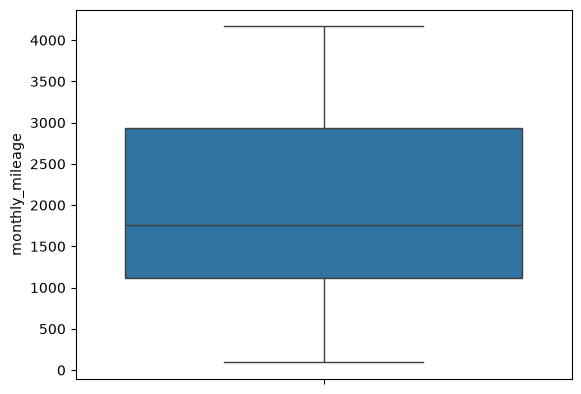

In [52]:
sns.boxplot(df_model['monthly_mileage'])

<Axes: ylabel='Year'>

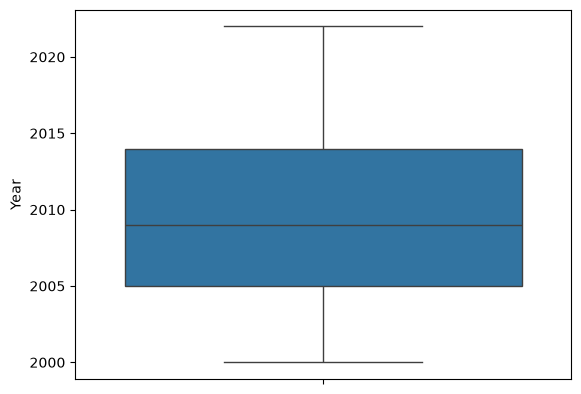

In [53]:
sns.boxplot(df_model['Year'])

<Axes: ylabel='Engine_Size'>

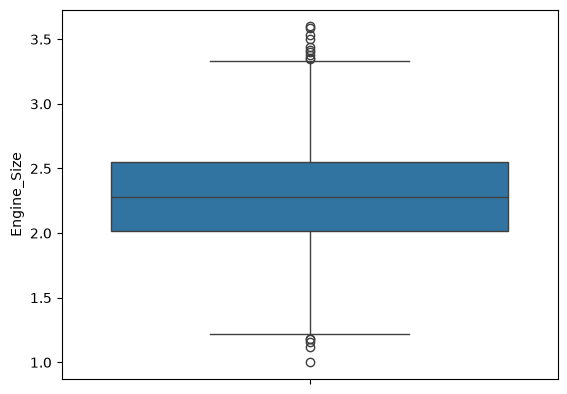

In [54]:
sns.boxplot(df_model['Engine_Size'])

<Axes: ylabel='Owners'>

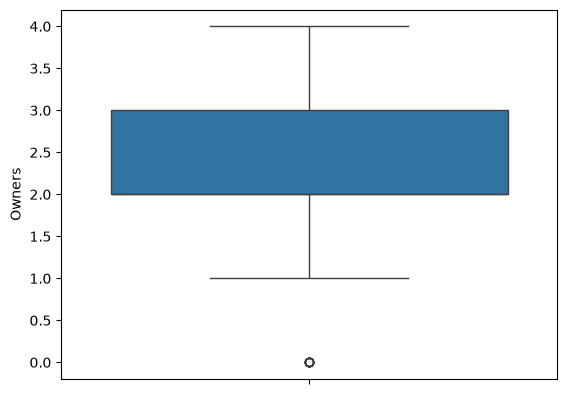

In [55]:
sns.boxplot(df_model['Owners'])

In [56]:
df_model = df_model[df_model['Owners'] != 0]
df = df_model

In [57]:
df.to_csv('cleaned_df_dataset_1.csv', index = False)

In [58]:
data = pd.read_csv('cleaned_df_dataset_1.csv')
data.info()
df = data

<class 'pandas.DataFrame'>
RangeIndex: 2219 entries, 0 to 2218
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   monthly_mileage  2219 non-null   float64
 1   Year             2219 non-null   int64  
 2   Engine_Size      2219 non-null   float64
 3   Warranty         2219 non-null   int64  
 4   Model            2219 non-null   str    
 5   Safety           2219 non-null   str    
 6   Condition        2219 non-null   str    
 7   Service_History  2219 non-null   str    
 8   Owners           2219 non-null   int64  
 9   Insurance        2219 non-null   str    
 10  Price            2219 non-null   float64
dtypes: float64(3), int64(3), str(5)
memory usage: 298.6 KB


### 1. Univariate Data Analysis

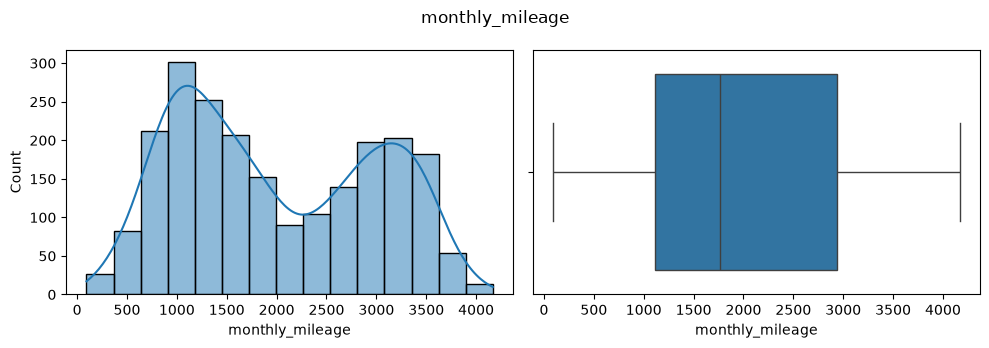

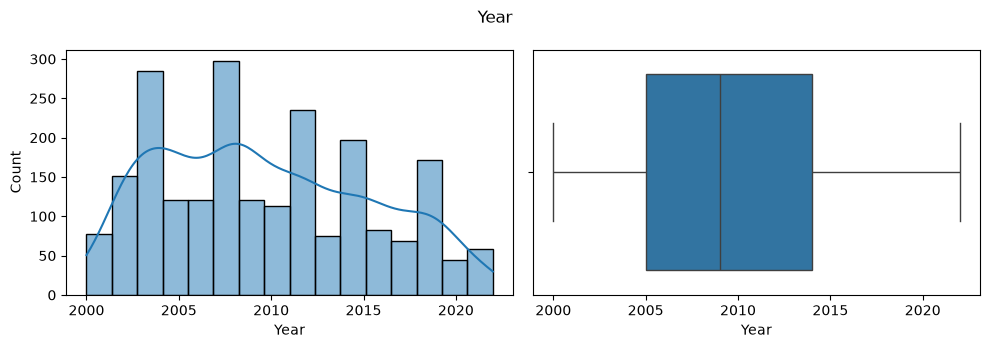

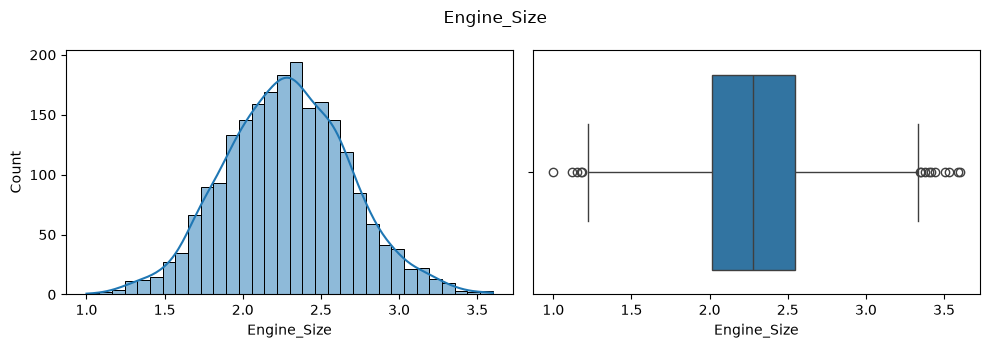

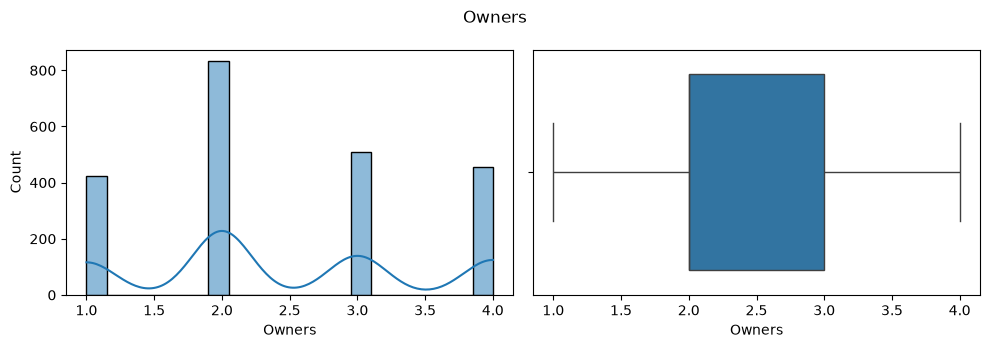

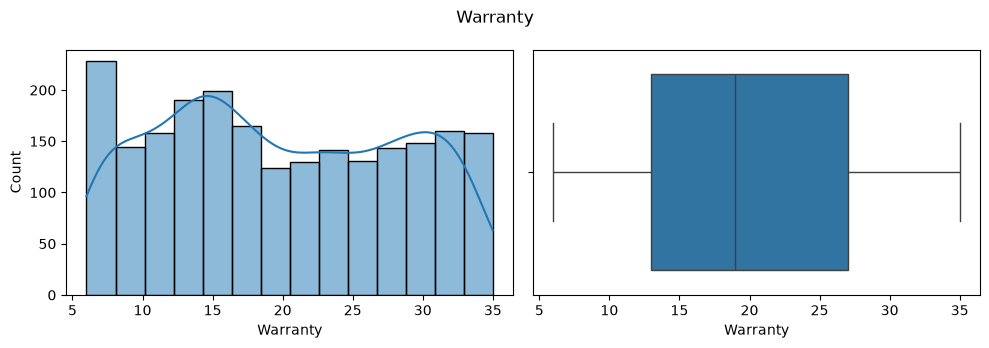

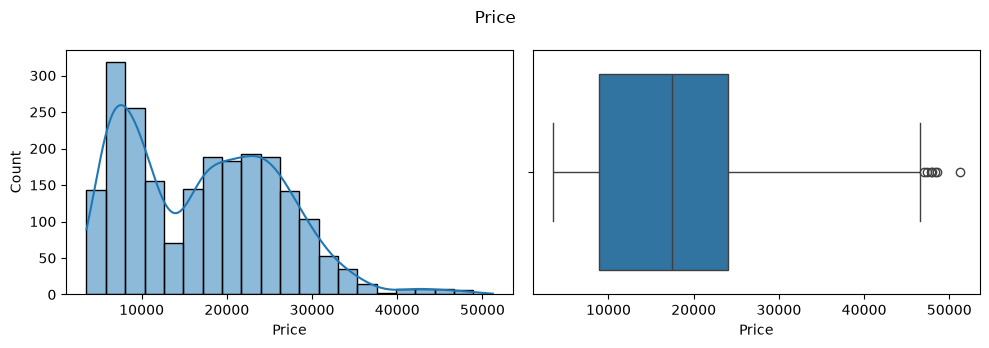

                     mean       50%      std       IQR  skew
monthly_mileage   1986.87   1760.43   993.55   1823.76  0.23
Year              2009.70   2009.00     5.68      9.00  0.29
Engine_Size          2.28      2.28     0.39      0.53  0.07
Owners               2.45      2.00     1.02      1.00  0.18
Warranty            19.75     19.00     8.42     14.00  0.10
Price            17250.99  17405.18  8968.43  15174.78  0.45


In [59]:
num_feats = ['monthly_mileage', 'Year', 'Engine_Size', 'Owners', 'Warranty']
cat_feats = ['Model','Condition','Insurance', 'Service_History',
             'Safety']

# Univariate numeric features and target variable
for c in num_feats + ['Price']:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    sns.histplot(df[c], kde=True, ax=ax[0])
    sns.boxplot(x=df[c], ax=ax[1])
    fig.suptitle(c); plt.tight_layout(); plt.show()

stats = df[num_feats + ['Price']].describe().T
stats['IQR'] = stats['75%'] - stats['25%']
stats['skew'] = df[num_feats + ['Price']].skew()
print(stats[['mean','50%','std','IQR','skew']].round(2))


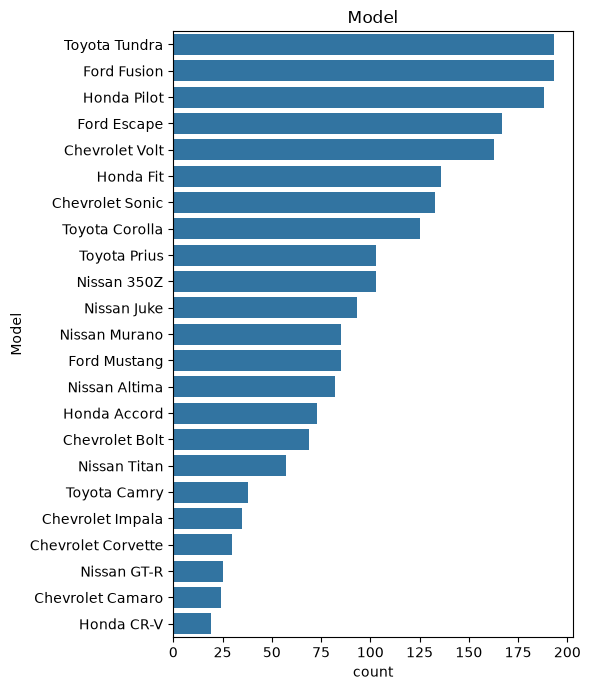

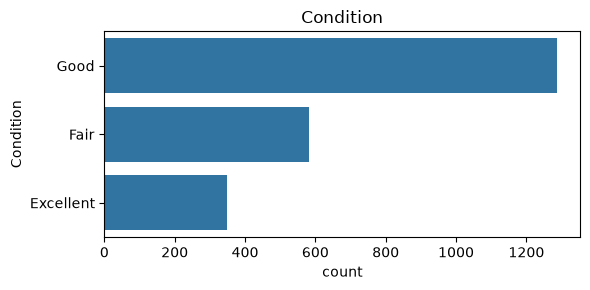

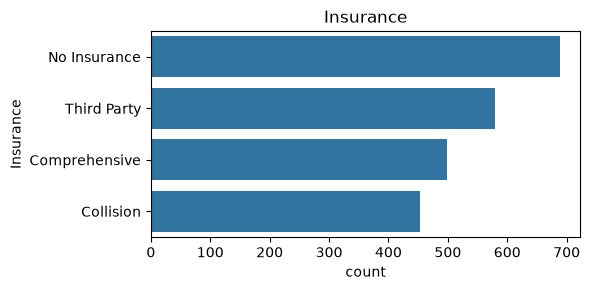

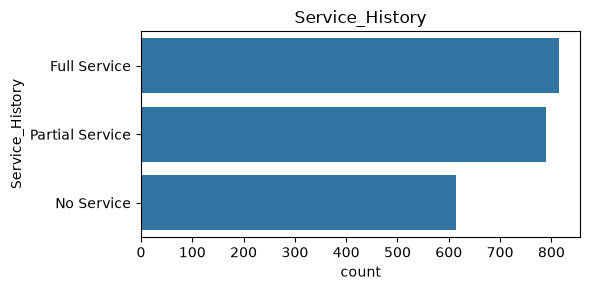

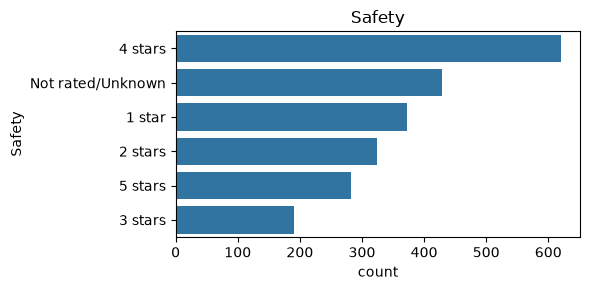

In [60]:
# Univariate categorical features
for c in cat_feats:
    order = df[c].value_counts().index
    plt.figure(figsize=(6, 3 if c != 'Model' else 7))
    sns.countplot(data=df, y=c, order=order)
    plt.title(c); plt.tight_layout(); plt.show()

### 2. Bivariate Data Analysis

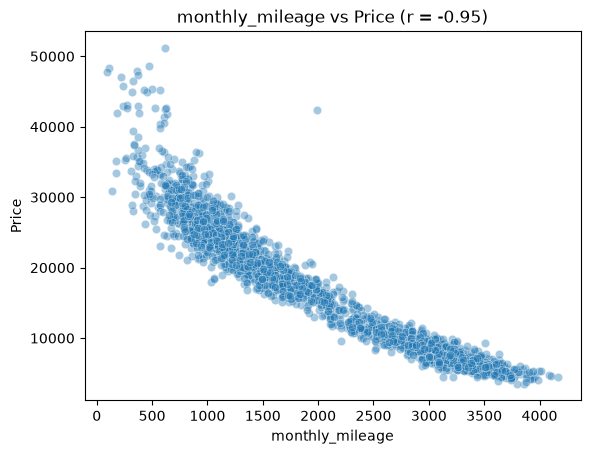

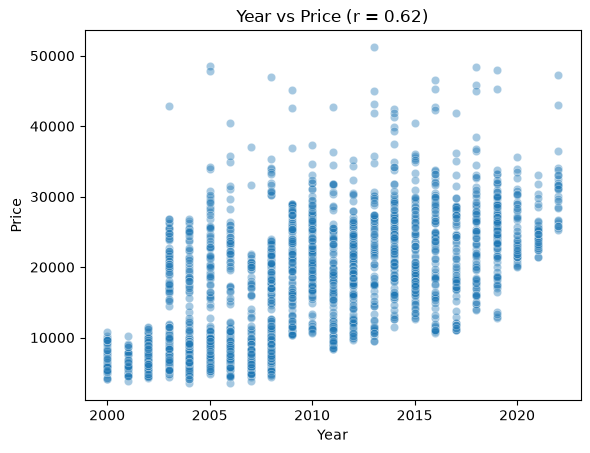

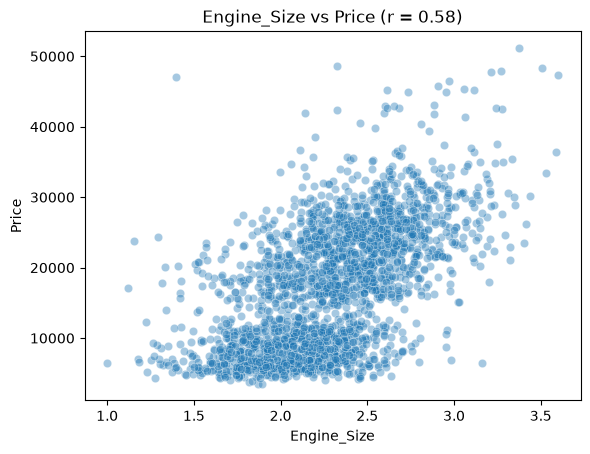

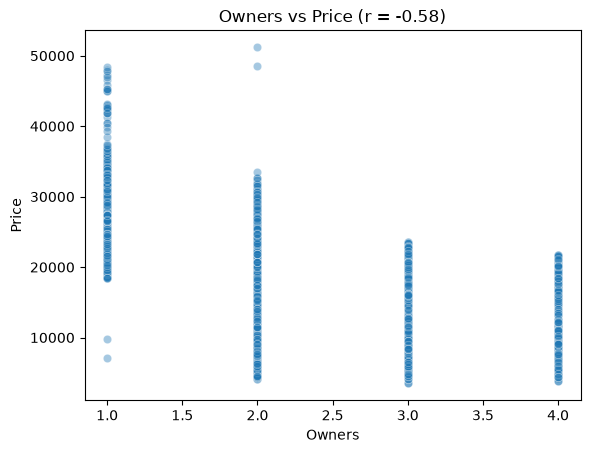

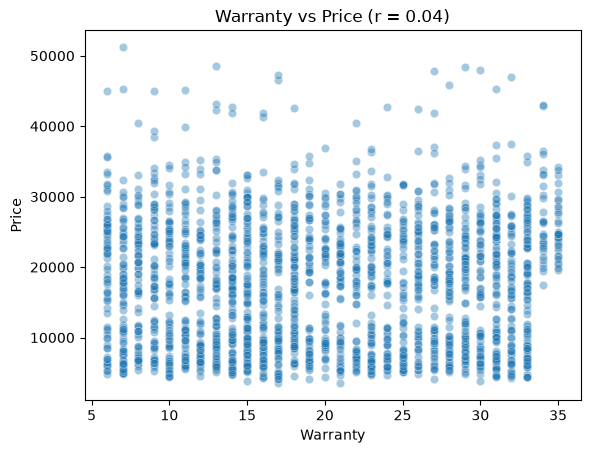

In [61]:
# Bivariate numeric features vs Price
for c in num_feats:
    sns.scatterplot(data=df, x=c, y='Price', alpha=.4)
    plt.title(f"{c} vs Price (r = {df[c].corr(df['Price']):.2f})")
    plt.show()

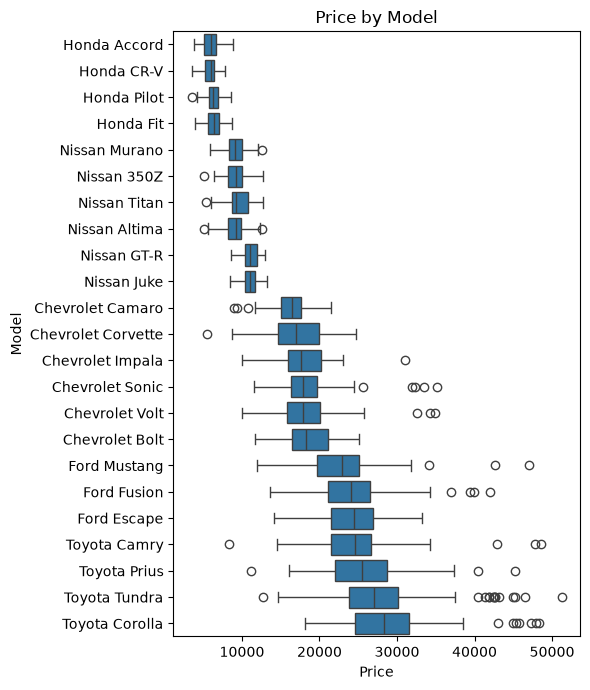

Model
Honda CR-V             5929.0
Honda Accord           5934.0
Honda Pilot            6280.0
Honda Fit              6313.0
Nissan Altima          9095.0
Nissan Murano          9138.0
Nissan 350Z            9166.0
Nissan Titan           9480.0
Nissan Juke           10958.0
Nissan GT-R           10967.0
Chevrolet Camaro      15908.0
Chevrolet Corvette    16901.0
Chevrolet Impala      18042.0
Chevrolet Volt        18142.0
Chevrolet Sonic       18334.0
Chevrolet Bolt        18443.0
Ford Mustang          23284.0
Ford Fusion           24196.0
Ford Escape           24231.0
Toyota Camry          25381.0
Toyota Prius          25765.0
Toyota Tundra         27390.0
Toyota Corolla        28851.0
Name: Price, dtype: float64


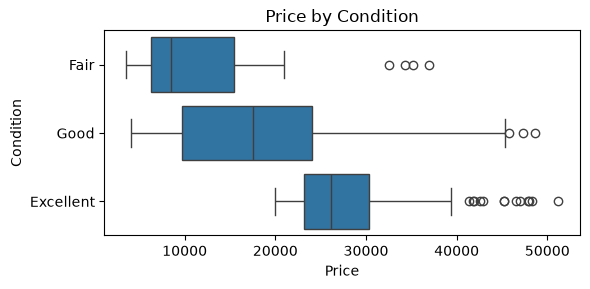

Condition
Fair         10560.0
Good         17568.0
Excellent    27240.0
Name: Price, dtype: float64


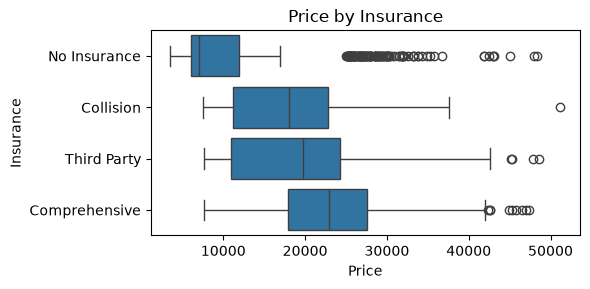

Insurance
No Insurance     11217.0
Collision        17758.0
Third Party      19103.0
Comprehensive    22969.0
Name: Price, dtype: float64


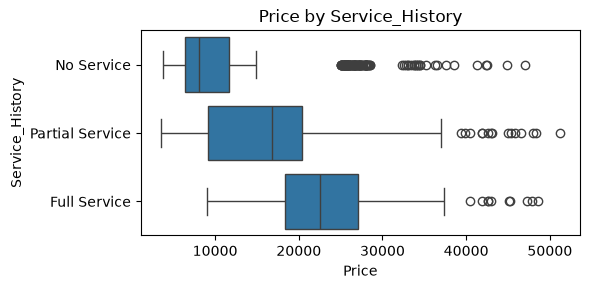

Service_History
No Service         11627.0
Partial Service    16330.0
Full Service       22381.0
Name: Price, dtype: float64


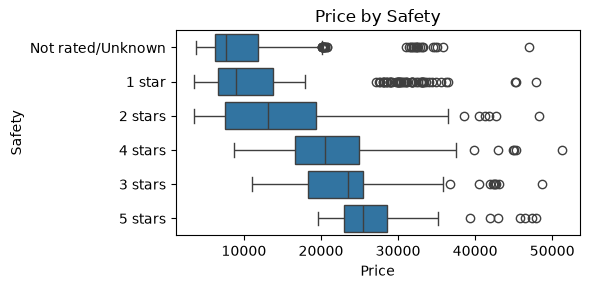

Safety
Not rated/Unknown    10355.0
1 star               12305.0
2 stars              14796.0
4 stars              20579.0
3 stars              22532.0
5 stars              26188.0
Name: Price, dtype: float64


In [62]:
# Bivariate categorical features vs Price
for c in cat_feats:
    order = df.groupby(c)['Price'].median().sort_values().index
    plt.figure(figsize=(6, 3 if c != 'Model' else 7))
    sns.boxplot(data=df, y=c, x='Price', order=order)
    plt.title(f"Price by {c}"); plt.tight_layout(); plt.show()
    print(df.groupby(c)['Price'].mean().round(0).sort_values())

In [63]:
# --- Predictive power table (r^2 and eta^2, comparable scales) ---
def eta_sq(data, cat, target='Price'):
    grand = data[target].mean()
    ss_b = data.groupby(cat)[target].apply(lambda s: len(s)*(s.mean()-grand)**2).sum()
    return ss_b / ((data[target]-grand)**2).sum()

power = {c: df[c].corr(df['Price'])**2 for c in num_feats}
power.update({c: eta_sq(df, c) for c in cat_feats})
print(pd.Series(power).sort_values(ascending=False).round(3))

monthly_mileage    0.903
Model              0.808
Year               0.388
Safety             0.371
Condition          0.342
Engine_Size        0.342
Owners             0.341
Insurance          0.243
Service_History    0.233
Warranty           0.002
dtype: float64


## Data Analysis

In [64]:
df = pd.read_csv('cleaned_df_dataset_1.csv')
df.head()

,monthly_mileage,Year,Engine_Size,Warranty,Model,Safety,Condition,Service_History,Owners,Insurance,Price
0,3020.474750,2007,1.655688,7,Nissan Altima,Not rated/Unknown,Fair,No Service,2,Third Party,8005.469674
1,894.742606,2019,2.696626,20,Toyota Corolla,5 stars,Excellent,Full Service,1,No Insurance,25385.241860
2,3496.160436,2004,1.642471,12,Honda CR-V,Not rated/Unknown,Fair,No Service,4,No Insurance,6553.601733
3,1037.247974,2020,2.044309,8,Toyota Corolla,3 stars,Good,Full Service,1,Collision,24381.083350
4,880.045753,2017,2.586011,35,Toyota Tundra,5 stars,Good,Partial Service,1,Comprehensive,28357.830640


In [65]:
df.isnull().sum()

monthly_mileage    0
Year               0
Engine_Size        0
Warranty           0
Model              0
Safety             0
Condition          0
Service_History    0
Owners             0
Insurance          0
Price              0
dtype: int64

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2219 entries, 0 to 2218
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   monthly_mileage  2219 non-null   float64
 1   Year             2219 non-null   int64  
 2   Engine_Size      2219 non-null   float64
 3   Warranty         2219 non-null   int64  
 4   Model            2219 non-null   str    
 5   Safety           2219 non-null   str    
 6   Condition        2219 non-null   str    
 7   Service_History  2219 non-null   str    
 8   Owners           2219 non-null   int64  
 9   Insurance        2219 non-null   str    
 10  Price            2219 non-null   float64
dtypes: float64(3), int64(3), str(5)
memory usage: 298.6 KB


In [67]:
df_model = df[[
    'monthly_mileage',
    'Year',
    'Engine_Size',
    'Warranty',
    'Model',
    'Safety',
    'Condition',
    'Service_History',
    'Owners',
    'Insurance',
    'Price',
]]

In [68]:
df_model

,monthly_mileage,Year,Engine_Size,Warranty,Model,Safety,Condition,Service_History,Owners,Insurance,Price
0,3020.474750,2007,1.655688,7,Nissan Altima,Not rated/Unknown,Fair,No Service,2,Third Party,8005.469674
1,894.742606,2019,2.696626,20,Toyota Corolla,5 stars,Excellent,Full Service,1,No Insurance,25385.241860
2,3496.160436,2004,1.642471,12,Honda CR-V,Not rated/Unknown,Fair,No Service,4,No Insurance,6553.601733
3,1037.247974,2020,2.044309,8,Toyota Corolla,3 stars,Good,Full Service,1,Collision,24381.083350
4,880.045753,2017,2.586011,35,Toyota Tundra,5 stars,Good,Partial Service,1,Comprehensive,28357.830640
...,...,...,...,...,...,...,...,...,...,...,...
2214,2051.008598,2013,2.238645,11,Chevrolet Sonic,2 stars,Good,Full Service,4,Comprehensive,15164.228470
2215,2965.163102,2007,2.283821,32,Honda Fit,Not rated/Unknown,Good,Partial Service,2,No Insurance,6250.307375
2216,1300.819060,2012,2.355598,30,Chevrolet Sonic,4 stars,Excellent,Full Service,1,Third Party,21614.535620
2217,3053.176775,2003,1.944553,26,Nissan Titan,1 star,Good,No Service,3,Collision,8373.305539


### Features and Target

In [69]:
features = [
    'monthly_mileage',
    'Year',
    'Engine_Size',
    'Warranty',
    'Model',
    'Safety',
    'Condition',
    'Service_History',
    'Owners',
    'Insurance'
]
target = ['Price']

### Train Test Split

In [70]:
X = df_model[features]
Y = df_model[target]

In [71]:
# now converting all the categorical values to numerical for regression model
X_encoded = pd.get_dummies(X, drop_first=True)
X = X_encoded
X

,monthly_mileage,Year,Engine_Size,Warranty,Owners,Model_Chevrolet Camaro,Model_Chevrolet Corvette,Model_Chevrolet Impala,Model_Chevrolet Sonic,Model_Chevrolet Volt,...,Safety_4 stars,Safety_5 stars,Safety_Not rated/Unknown,Condition_Fair,Condition_Good,Service_History_No Service,Service_History_Partial Service,Insurance_Comprehensive,Insurance_No Insurance,Insurance_Third Party
0,3020.474750,2007,1.655688,7,2,False,False,False,False,False,...,False,False,True,True,False,True,False,False,False,True
1,894.742606,2019,2.696626,20,1,False,False,False,False,False,...,False,True,False,False,False,False,False,False,True,False
2,3496.160436,2004,1.642471,12,4,False,False,False,False,False,...,False,False,True,True,False,True,False,False,True,False
3,1037.247974,2020,2.044309,8,1,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,880.045753,2017,2.586011,35,1,False,False,False,False,False,...,False,True,False,False,True,False,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2214,2051.008598,2013,2.238645,11,4,False,False,False,True,False,...,False,False,False,False,True,False,False,True,False,False
2215,2965.163102,2007,2.283821,32,2,False,False,False,False,False,...,False,False,True,False,True,False,True,False,True,False
2216,1300.819060,2012,2.355598,30,1,False,False,False,True,False,...,True,False,False,False,False,False,False,False,False,True
2217,3053.176775,2003,1.944553,26,3,False,False,False,False,False,...,False,False,False,False,True,True,False,False,False,False


In [72]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size = 0.2, random_state = 42)

### Feature Scaling

In [73]:
scaler = StandardScaler()

In [74]:
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

In [75]:
X_train_scale

array([[ 0.24311031, -0.3075036 , -0.96159407, ...,  1.83921615,
        -0.67182523, -0.59057954],
       [-1.09910916,  1.80466238,  2.12422081, ...,  1.83921615,
        -0.67182523, -0.59057954],
       [-0.86077408,  1.62864855,  1.43548277, ..., -0.54370988,
        -0.67182523,  1.69325202],
       ...,
       [-1.17351353, -0.8355451 ,  0.76285627, ...,  1.83921615,
        -0.67182523, -0.59057954],
       [ 1.26287873, -0.8355451 , -0.88786031, ..., -0.54370988,
         1.48848235, -0.59057954],
       [-0.6947194 ,  0.04452406,  0.30840917, ...,  1.83921615,
        -0.67182523, -0.59057954]], shape=(1775, 39))

## Model Training

### 1. Linear regression

In [76]:
model = LinearRegression()

In [77]:
model.fit(X_train_scale, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 39)","[[-7541.33, 156.37, 548.48,..., 277.19, 477.21, 154.58]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[17257.6]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,39
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(39)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](39,)","[93.25,58.47,53.62,...,16.99,10.68, 6.36]"


In [78]:
Y_pred = model.predict(X_test_scale)

In [79]:
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)
print(f'Mean Absolute Error: {mae}')
print(f'Mean Squared Error: {mse}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R2 Score: {r2}')

Mean Absolute Error: 1577.5911687778237
Mean Squared Error: 5919334.442679376
Root Mean Squared Error: 2432.9682370880587
R2 Score: 0.92841591806773


### Visualization

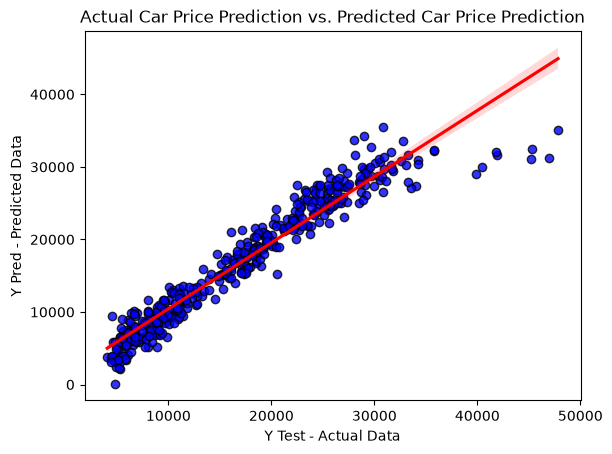

In [80]:
sns.regplot(x = Y_test, y = Y_pred, color = 'blue', line_kws={'color':'red'}, scatter_kws = {'edgecolor':'black'})
plt.xlabel('Y Test - Actual Data')
plt.ylabel('Y Pred - Predicted Data')
plt.title('Actual Car Price Prediction vs. Predicted Car Price Prediction')
plt.show()

### 2. Decision Tree(regression)

In [81]:
# Initialize and train
dt_model = DecisionTreeRegressor(
    max_depth=3,
    min_samples_split=2,
    random_state=42
) # max_depth prevents overfitting

In [82]:
X = df_model[features]
Y = df_model[target]

In [83]:
# feature_training, feature_testing, target_training, target_testing
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

In [84]:
dt_model.fit(X_train_scale, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

In [85]:
Y_pred = dt_model.predict(X_test_scale)

In [86]:
print(f'R-squared Score: {r2_score(Y_test, Y_pred):.2f}')
print(f'Mean Squared Error: {mean_squared_error(Y_test, Y_pred):.2f}')
print(f'Mean Absolute Error: {mean_absolute_error(Y_test, Y_pred):.2f}')

R-squared Score: 0.92
Mean Squared Error: 6315668.45
Mean Absolute Error: 1721.65


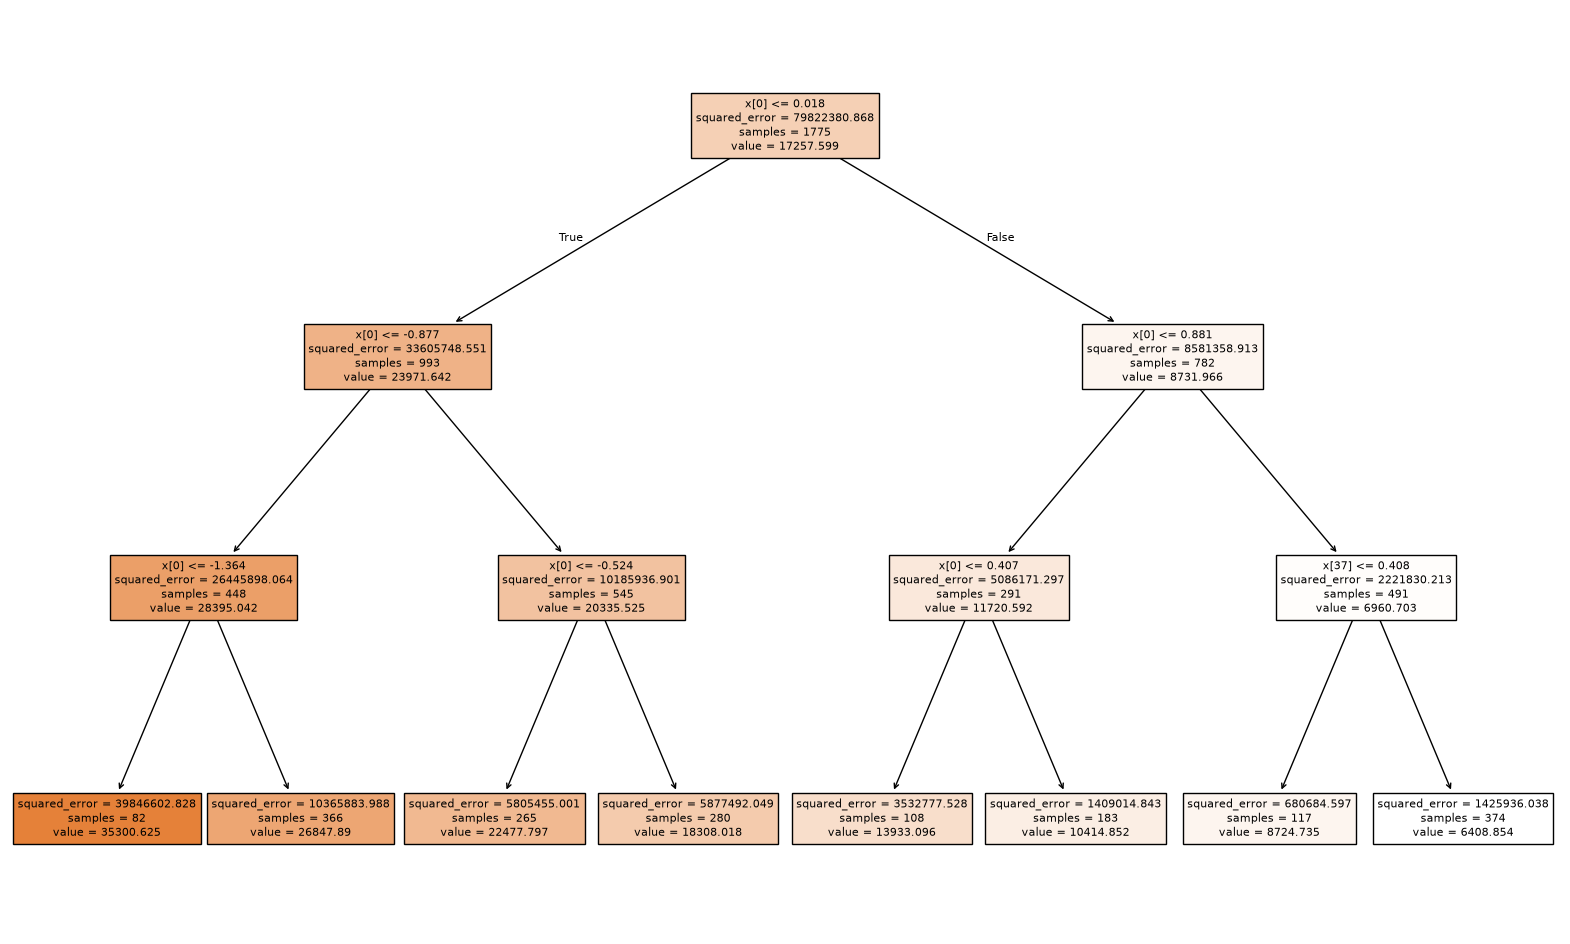

In [87]:
plt.figure(figsize=(20, 12))
plot_tree(
    dt_model, 
    filled=True
)
plt.show()

### 3. Random Forest Regressor

In [88]:
X = df_model[features]
Y = df_model[target]

In [89]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

In [90]:
rf_model.fit(X_train_scale, Y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [91]:
Y_pred = rf_model.predict(X_test_scale)

In [92]:
# Evaluate
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)
print(f'Mean Absolute Error: {mae}')
print(f'Mean Squared Error: {mse}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R2 Score: {r2}')

Mean Absolute Error: 1208.775332399437
Mean Squared Error: 4277996.172771798
Root Mean Squared Error: 2068.331736635059
R2 Score: 0.948265057245352


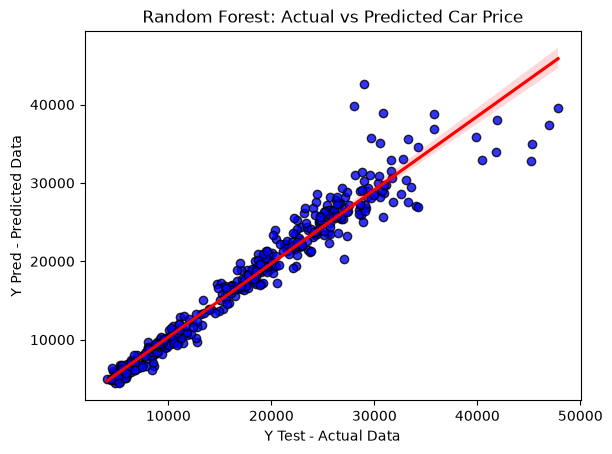

In [93]:
sns.regplot(x=Y_test, y=Y_pred, color='blue', line_kws={'color':'red'}, scatter_kws={'edgecolor':'black'})
plt.xlabel('Y Test - Actual Data')
plt.ylabel('Y Pred - Predicted Data')
plt.title('Random Forest: Actual vs Predicted Car Price')
plt.show()

### Model Comparision

In [94]:
# 1. Prepare predictors and target
X_compare = pd.get_dummies(df_model[features], drop_first=True)
y_compare = df_model['Price']

# 2. Train-test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_compare, y_compare, test_size=0.2, random_state=42
)

# 3. Scale features for Linear Regression
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

# --- 4. Linear Regression ---
lr = LinearRegression()
lr.fit(X_train_c_scaled, y_train_c)
lr_pred = lr.predict(X_test_c_scaled)

lr_mae = mean_absolute_error(y_test_c, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test_c, lr_pred))
lr_r2 = r2_score(y_test_c, lr_pred)

print("--- Linear Regression ---")
print(f"MAE: {lr_mae:.3f}, RMSE: {lr_rmse:.3f}, R2: {lr_r2:.3f}\n")


# --- 5. Decision Tree ---
dt = DecisionTreeRegressor(max_depth=3, random_state=42)
dt.fit(X_train_c, y_train_c)
dt_pred = dt.predict(X_test_c)

dt_mae = mean_absolute_error(y_test_c, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test_c, dt_pred))
dt_r2 = r2_score(y_test_c, dt_pred)

print("--- Decision Tree ---")
print(f"MAE: {dt_mae:.3f}, RMSE: {dt_rmse:.3f}, R2: {dt_r2:.3f}\n")


# --- 6. Random Forest ---
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_c, y_train_c)
rf_pred = rf.predict(X_test_c)

rf_mae = mean_absolute_error(y_test_c, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test_c, rf_pred))
rf_r2 = r2_score(y_test_c, rf_pred)

print("--- Random Forest ---")
print(f"MAE: {rf_mae:.3f}, RMSE: {rf_rmse:.3f}, R2: {rf_r2:.3f}")

--- Linear Regression ---
MAE: 1577.591, RMSE: 2432.968, R2: 0.928

--- Decision Tree ---
MAE: 1721.648, RMSE: 2513.099, R2: 0.924

--- Random Forest ---
MAE: 1210.519, RMSE: 2070.386, R2: 0.948


In [95]:
print(r2_score(y_train_c, lr.predict(X_train_c_scaled)))   # Linear regression
print(r2_score(y_train_c, dt.predict(X_train_c)))          # Regression tree, depth 3
print(r2_score(y_train_c, rf.predict(X_train_c)))          # Random forest (final)
print(r2_score(Y_train, rf_model.predict(X_train_scale)))  # Random forest, limited (depth 10)

0.9281708903793972
0.9188493459576156
0.9921853005369781
0.9921938240471373
